# ViTA: 효율적인 Video-to-Text 변환

이 노트북은 ViTA 논문의 아이디어를 이 강의(4강) 5장의 Video RAG 파이프라인에 맞춰 단순화해 실습합니다.

- 긴 영상을 클립 단위로 나눕니다.
- 각 클립을 빠른 요약 pass와 세부 보강 pass로 변환합니다.
- 변환된 텍스트를 임베딩해 검색 가능한 형태로 저장합니다.

> 실제 ViTA는 lightweight VLM과 heavyweight VLM을 조합합니다. 이 실습은 로컬 환경을 단순하게 유지하기 위해 같은 Qwen3-VL 모델을 사용하되, 프레임 수·해상도·출력 토큰 수를 다르게 설정해 lightweight/heavyweight 역할을 흉내냅니다.

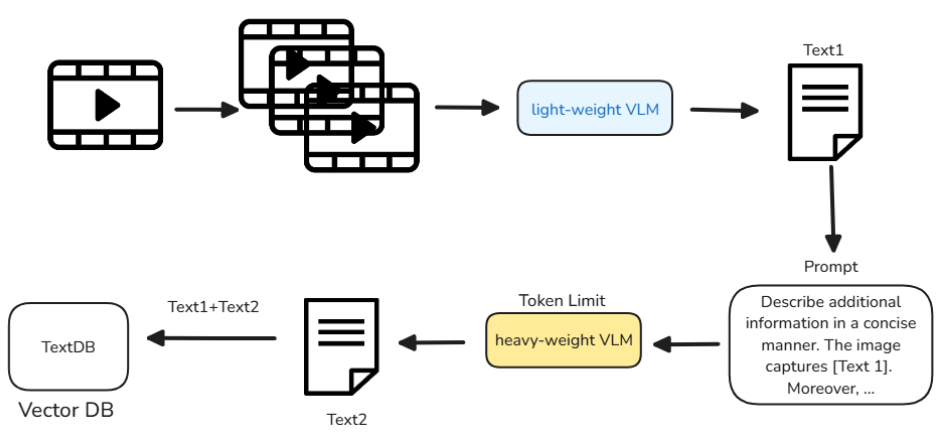

## 사전 준비

Ollama 모델이 없다면 터미널에서 먼저 실행합니다.

```bash
ollama pull qwen3-vl:4b
ollama pull qwen3-embedding:0.6b
```

실습 영상은 `data/4_long_video_uruguay_1949.mp4`를 사용합니다.

In [1]:
from pathlib import Path
import time

import chromadb
from tqdm.auto import tqdm

import video_utils as vu

VIDEO = Path("data/4_long_video_uruguay_1949.mp4")
info = vu.get_video_info(VIDEO)
info

D:\develop\github\course_VLM\4. Video Language Model\examples\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'fps': 29.97,
 'frame_count': 32384,
 'duration_sec': 1080.5472138805474,
 'width': 320,
 'height': 240}

## 1. 긴 영상을 클립으로 나누기

긴 영상 전체를 한 번에 VLM에 넣기 어렵기 때문에, 먼저 일정 길이의 클립으로 나눕니다.

- 너무 긴 클립: 요약이 뭉뚱그려져 검색 정확도 저하
- 너무 짧은 클립: VLM 호출 횟수와 임베딩 수 증가
- 실습에서는 실행 시간을 줄이기 위해 앞부분 몇 개 클립만 사용합니다.

In [2]:
def make_clips(video_path, clip_sec=180, max_clips=4):
    info = vu.get_video_info(video_path)
    clips = []
    start = 0.0
    idx = 0
    while start < info["duration_sec"] and idx < max_clips:
        end = min(start + clip_sec, info["duration_sec"])
        clips.append({
            "clip_id": idx,
            "start": start,
            "end": end,
            "label": f"clip {idx}: {start:.0f}s~{end:.0f}s",
        })
        start = end
        idx += 1
    return clips

clips = make_clips(VIDEO, clip_sec=180, max_clips=4)
clips

[{'clip_id': 0, 'start': 0.0, 'end': 180.0, 'label': 'clip 0: 0s~180s'},
 {'clip_id': 1, 'start': 180.0, 'end': 360.0, 'label': 'clip 1: 180s~360s'},
 {'clip_id': 2, 'start': 360.0, 'end': 540.0, 'label': 'clip 2: 360s~540s'},
 {'clip_id': 3, 'start': 540.0, 'end': 720.0, 'label': 'clip 3: 540s~720s'}]

## 2. Fast Pass: 빠른 장면 요약

Fast pass는 lightweight VLM 역할입니다.

- 적은 프레임 수
- 낮은 해상도
- 짧은 출력 토큰

목표는 클립의 대략적인 장면과 주제를 빠르게 파악하는 것입니다.

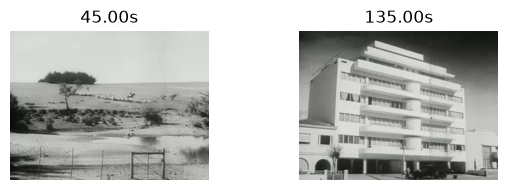

흑백 사진에서 다층 구조의 대형 건물이 보이며, 주변에는 나무와 차량이 주차되어 있고 앞쪽에 울타리가 설치된 공간이 나타납니다. 건물은 직선적인 형태로 단순한 디자인을 띠고 있으며, 주변 환경은 비교적 평탄한 풍경입니다.


In [3]:
FAST_PROMPT = """
이 클립의 핵심 장면을 검색용으로 아주 짧게 요약해줘.

작성 규칙:
- 2~3문장으로만 작성
- 보이는 장소, 주요 객체, 사람/활동 중심으로 작성
- 확인되지 않는 내용은 추측하지 않기
"""

def fast_overview(clip):
    frames = vu.extract_frames_range(
        VIDEO,
        clip["start"],
        clip["end"],
        n_frames=2,
        max_width=384,
    )
    text = vu.ask_video(
        frames,
        FAST_PROMPT,
        temperature=0.1,
        num_predict=96,
    )
    return frames, text

fast_frames, fast_text = fast_overview(clips[0])
vu.show_frames(fast_frames)
print(fast_text)

## 3. Detail Pass: 부족한 정보만 보강

Detail pass는 heavyweight VLM 역할입니다.

중요한 점은 큰 모델에게 전체를 다시 길게 설명시키지 않는 것입니다.

- fast pass 요약을 함께 전달
- 중복 설명 금지
- 검색에 도움이 되는 세부 정보만 짧게 보강
- 출력 토큰 수 제한

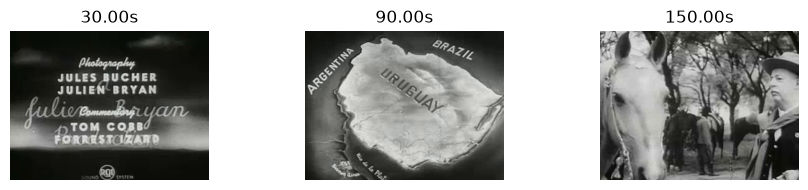

- 크레딧 화면에서 RCA 로고와 아르헨티나·브라질 지도가 표시됨  
- 말과 나무를 배경으로 한 외부 장면에서 인물이 대화하는 모습  
- 흑백 촬영으로 보이는 1940년대 영화 스타일의 분위기


In [4]:
def detail_refine(clip, overview):
    frames = vu.extract_frames_range(
        VIDEO,
        clip["start"],
        clip["end"],
        n_frames=3,
        max_width=512,
    )
    prompt = f"""
아래는 같은 클립에 대한 빠른 요약이야.

[빠른 요약]
{overview}

너의 역할은 빠른 요약에 이미 있는 내용을 반복하지 않고, 검색에 도움이 되는 세부 정보만 보강하는 것이다.

작성 규칙:
- 장소/객체/행동/장면 분위기 중 빠진 정보만 추가
- 3~5개의 짧은 bullet로 작성
- 영상에서 확인되는 내용만 작성
- 검색 키워드가 될 만한 명사를 구체적으로 포함
"""
    text = vu.ask_video(
        frames,
        prompt,
        temperature=0.1,
        num_predict=160,
    )
    return frames, text

detail_frames, detail_text = detail_refine(clips[0], fast_text)
vu.show_frames(detail_frames)
print(detail_text)

## 4. ViTA 스타일 변환 함수 만들기

각 클립에 대해 다음 정보를 저장합니다.

- 빠른 요약
- 세부 보강 설명
- 두 텍스트를 합친 검색용 문서
- 처리 시간

In [5]:
def vita_convert_clip(clip):
    t0 = time.perf_counter()
    _, overview = fast_overview(clip)
    _, detail = detail_refine(clip, overview)
    elapsed = time.perf_counter() - t0
    document = f"""
[{clip['label']}]

빠른 요약:
{overview}

세부 보강:
{detail}
""".strip()
    return {
        **clip,
        "overview": overview,
        "detail": detail,
        "document": document,
        "elapsed_sec": elapsed,
    }

vita_docs = []
for clip in tqdm(clips):
    vita_docs.append(vita_convert_clip(clip))

for doc in vita_docs:
    print("=" * 80)
    print(doc["document"])
    print(f"\n처리 시간: {doc['elapsed_sec']:.1f}초")


  0%|          | 0/4 [00:00<?, ?it/s]


 25%|██▌       | 1/4 [02:59<08:58, 179.48s/it]


 50%|█████     | 2/4 [04:50<04:37, 138.93s/it]


 75%|███████▌  | 3/4 [08:11<02:47, 167.27s/it]


100%|██████████| 4/4 [09:45<00:00, 138.38s/it]


100%|██████████| 4/4 [09:45<00:00, 146.28s/it]

[clip 0: 0s~180s]

빠른 요약:
흑백 사진에서 현대식 다층 건물이 주로 보이며, 건물 주변에는 나무와 차량이 주차되어 있습니다. 또한, 건물 앞쪽에 울타리가 설치되어 있습니다.

세부 보강:
- 영화 개봉 크레딧 화면에 'Argentina'와 'Brazil' 국가 이름이 지도 형태로 표기되어 있으며, 'Photography by Jules Bucher' 및 'Commentary by Tom Cobb' 등의 제작 정보가 포함됨  
- 2번 프레임에서 흑백 사진으로 보이는 역사적 의상(예: 모자, 코트)을 입은 인물들이 말과 함께 나무가 우거진 외부 장면에 등장하며, 한 남자가 말을 가리키는 행동이 관찰됨  
- 크레딧 하단에는 'RCA Sound System' 로고가 표시되어 있어 영화의 음향 시스템을 나타냄

처리 시간: 179.5초
[clip 1: 180s~360s]

빠른 요약:
검은 모자를 쓰고 흑색 옷을 입은 남자가 라운드한 물체를 손에 들고 검사하고 있다. 배경은 단순하며 구체적인 장소는 확인되지 않았다.

세부 보강:
- 개방된 초원과 나무가 우거진 풍경에서 황소로 끌린 마차와 달리는 말 그룹이 움직이고 있다.  
- 검은 모자와 흑색 옷을 입은 남자가 라운드한 물체(바이럴)를 손에 들고 검사하는 모습.  
- 역사적 풍경으로 보이는 흑백 클립에서의 장면.

처리 시간: 110.5초
[clip 2: 360s~540s]

빠른 요약:
검정백색 사진에서 공원에서 여성들이 테이블 주위에 앉아 식사를 하고 있는 장면입니다. 여성들은 빛나는 드레스와 모자로 차분하게 소통하며, 배경에는 나무와 건물이 보입니다.

세부 보강:
- 검정백색 사진에서 390초 프레임은 교실 내부의 장면으로, 학생들이 책상에 앉아 있는 모습과 창문 너머로 서서 움직이는 다른 학생들이 보인다.  
- 450초 프레임은 해안가 풍경으로, 바다와 건물(예: 타워)이 위치한 넓은 초원 위에서 사람들이 산책하고 있으며, 오른쪽에는 긴 철제 구조물이 보인다.  
- 1번 프레임의

## 5. Baseline과 비교해 보기

Baseline은 하나의 VLM에게 클립을 한 번에 자세히 설명하도록 요청하는 방식입니다.

실습 시간이 길어질 수 있으므로 첫 번째 클립만 비교합니다.

In [6]:
BASELINE_PROMPT = """
이 클립을 Video RAG 검색에 사용할 수 있도록 자세히 설명해줘.

포함할 내용:
- 장소와 배경
- 주요 객체와 사람
- 눈에 띄는 활동
- 검색 키워드가 될 만한 단어

확인되는 내용만 작성하고, 너무 추상적으로 요약하지 마.
"""

def baseline_convert_clip(clip):
    frames = vu.extract_frames_range(
        VIDEO,
        clip["start"],
        clip["end"],
        n_frames=3,
        max_width=512,
    )
    t0 = time.perf_counter()
    text = vu.ask_video(
        frames,
        BASELINE_PROMPT,
        temperature=0.1,
        num_predict=512,
    )
    elapsed = time.perf_counter() - t0
    return {"text": text, "elapsed_sec": elapsed}

baseline = baseline_convert_clip(clips[0])
vita_first = vita_docs[0]

print("[Baseline]")
print(f"시간: {baseline['elapsed_sec']:.1f}초 / 글자 수: {len(baseline['text'])}")
print(baseline["text"])

print("\n[ViTA 스타일]")
print(f"시간: {vita_first['elapsed_sec']:.1f}초 / 글자 수: {len(vita_first['document'])}")
print(vita_first["document"])

[Baseline]
시간: 27.3초 / 글자 수: 246
1번 프레임(30.0초):  
- **장소와 배경**: 영화 제목 카드 또는 끝 credits 화면, 남미 지도(아르헨티나, 브라질 표시)가 배경으로 나타납니다.  
- **주요 객체와 사람**: "Photography JULES BUCHER JULIEN BRYAN", "Commentary TOM COBB FOREST LLOYD" 등의 텍스트, RCA 소리 시스템 로고, 지도 위에 표시된 국가 이름(아르헨티나, 브라질).  
- **눈에

[ViTA 스타일]
시간: 179.5초 / 글자 수: 408
[clip 0: 0s~180s]

빠른 요약:
흑백 사진에서 현대식 다층 건물이 주로 보이며, 건물 주변에는 나무와 차량이 주차되어 있습니다. 또한, 건물 앞쪽에 울타리가 설치되어 있습니다.

세부 보강:
- 영화 개봉 크레딧 화면에 'Argentina'와 'Brazil' 국가 이름이 지도 형태로 표기되어 있으며, 'Photography by Jules Bucher' 및 'Commentary by Tom Cobb' 등의 제작 정보가 포함됨  
- 2번 프레임에서 흑백 사진으로 보이는 역사적 의상(예: 모자, 코트)을 입은 인물들이 말과 함께 나무가 우거진 외부 장면에 등장하며, 한 남자가 말을 가리키는 행동이 관찰됨  
- 크레딧 하단에는 'RCA Sound System' 로고가 표시되어 있어 영화의 음향 시스템을 나타냄


## 6. Vector DB에 저장하기

ViTA 스타일로 만든 텍스트를 임베딩해 Chroma에 저장합니다.

저장 대상은 원본 영상이 아니라, 클립별로 생성된 검색용 텍스트입니다.

In [7]:
client = chromadb.Client()

try:
    client.delete_collection("vita_video_text")
except Exception:
    pass

collection = client.create_collection("vita_video_text")

collection.add(
    ids=[f"clip_{d['clip_id']}" for d in vita_docs],
    embeddings=[vu.embed_text(d["document"]) for d in vita_docs],
    documents=[d["document"] for d in vita_docs],
    metadatas=[
        {
            "clip_id": d["clip_id"],
            "start": d["start"],
            "end": d["end"],
        }
        for d in vita_docs
    ],
)

collection.count()

4

## 7. 검색 테스트

사용자 질문을 임베딩한 뒤 가장 관련 있는 클립 텍스트를 검색합니다.

검색 결과가 좋아지려면 video-to-text 변환 결과에 검색 가능한 명사와 장면 정보가 충분히 들어 있어야 합니다.

In [8]:
def vita_search(question, top_k=2):
    q_embedding = vu.embed_text(question)
    result = collection.query(query_embeddings=[q_embedding], n_results=top_k)

    for doc, meta, dist in zip(
        result["documents"][0],
        result["metadatas"][0],
        result["distances"][0],
    ):
        print("=" * 80)
        print(f"구간: {meta['start']:.0f}s~{meta['end']:.0f}s / distance={dist:.4f}")
        print(doc)

vita_search("도시의 거리나 건물이 나오는 장면을 찾아줘")

구간: 540s~720s / distance=0.9446
[clip 3: 540s~720s]

빠른 요약:
흑백 해변 풍경에서 수영하고 산책하는 사람들이 보인다.

세부 보강:
- 금속 케이스 구조물(570초)과 곡선형 계단(630초)이 조합된 도시 건설 현장  
- 흰색 유니폼을 입은 인력들이 계단을 걷고 관찰하는 모습  
- 배경의 나무와 주거용 건물이 공원 풍경과 결합된 산업적 분위기
구간: 0s~180s / distance=1.0697
[clip 0: 0s~180s]

빠른 요약:
흑백 사진에서 현대식 다층 건물이 주로 보이며, 건물 주변에는 나무와 차량이 주차되어 있습니다. 또한, 건물 앞쪽에 울타리가 설치되어 있습니다.

세부 보강:
- 영화 개봉 크레딧 화면에 'Argentina'와 'Brazil' 국가 이름이 지도 형태로 표기되어 있으며, 'Photography by Jules Bucher' 및 'Commentary by Tom Cobb' 등의 제작 정보가 포함됨  
- 2번 프레임에서 흑백 사진으로 보이는 역사적 의상(예: 모자, 코트)을 입은 인물들이 말과 함께 나무가 우거진 외부 장면에 등장하며, 한 남자가 말을 가리키는 행동이 관찰됨  
- 크레딧 하단에는 'RCA Sound System' 로고가 표시되어 있어 영화의 음향 시스템을 나타냄


## 정리

ViTA의 핵심은 모델 파라미터를 튜닝하는 것이 아니라, **Video-to-Text 변환 파이프라인을 효율화**하는 것입니다.

- 긴 영상은 클립 단위로 나눠야 합니다.
- 큰 VLM을 모든 클립에 길게 쓰면 비용과 시간이 커집니다.
- 빠른 요약 + 짧은 세부 보강으로 검색에 필요한 정보를 밀도 있게 만들 수 있습니다.
- 최종 품질은 프레임 샘플링, 토큰 제한, 프롬프트 설계에 크게 좌우됩니다.